<a href="https://colab.research.google.com/github/dvinueza-ops/gdp-dashboard/blob/main/Taller_Practico_02_Grupo02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller Práctico 2: Priorizar y prototipar recomendaciones de productos similares para Compra Ya

**Universidad Internacional del Ecuador (UIDE)** · Maestría en Ciencia de Datos y Máquinas de Aprendizaje con mención en Inteligencia Artificial

**Materia:** Machine Learning No Supervisado y Análisis Multivariante

**Docente:** Manuel Eugenio Morocho Cayamcela, Ph.D.

**Semana 2:** Detección de Patrones y Representación Semántica ·

**Fecha:** 22 de noviembre de 2026

**Grupo 2**

| Integrante |
|---|
| Alex David Achiña Farinango |
| Daniel Patricio Vinueza López |
| José Luis Criollo Caiza |

---

Este notebook sigue el orden del enunciado. Primero se fija el criterio para elegir cuál de los tres proyectos de Compra Ya conviene desarrollar este trimestre. Después, en el **Bloque A**, se construye un sistema de recomendación por similitud de contenido sobre `catalogo_productos.csv`: se exploran las descripciones, se preprocesan, se comparan representaciones TF-IDF con unigramas y con bigramas, se calcula la similitud coseno y se evalúan las recomendaciones con criterio de negocio. En el **Bloque B** se hace la exploración breve de transacciones inusuales con Isolation Forest sobre `transacciones_sinteticas.csv`. La recomendación a la dirección se arma al final, con la evidencia obtenida en cada paso.

### Índice
0. Configuración y carga reproducible de los datos
1. Contexto y criterio de priorización de los tres proyectos
2. **Bloque A — Recomendación por similitud de contenido**
   * Paso 1 — Exploración de las descripciones de producto
   * Paso 2 — Preprocesamiento del texto y comparación de unigramas y bigramas
   * Paso 3 — TF-IDF, similitud coseno y búsqueda de similares
   * Paso 4 — Evaluación cualitativa de las recomendaciones
   * Paso 5 — Limitaciones de TF-IDF, alternativas y productos recién publicados
3. **Bloque B — Complemento breve de detección con Isolation Forest**
4. Recomendación por contenido frente a detección de casos inusuales
5. Recomendación final a la dirección de Compra Ya
6. Bitácora de decisiones, parámetros y semillas

## 0. Configuración y carga reproducible de los datos

* Lee ambos CSV **directamente del repositorio del docente en GitHub**, para que todo el grupo trabaje con los mismos archivos. Si no hay internet, busca una copia local con el mismo nombre.
* Imprime la huella SHA-256 de cada archivo para verificar que son los mismos datos.
* Usa una sola semilla (`semilla = 42`) en todo lo que tiene aleatoriedad.

Librerías y para qué se usan:

* `pandas` y `numpy`: manejo de tablas y cálculos.
* `matplotlib`: gráficos.
* `sklearn.feature_extraction.text.TfidfVectorizer`: representación TF-IDF de las descripciones.
* `sklearn.metrics.pairwise.cosine_similarity`: similitud coseno entre vectores.
* `sklearn.ensemble.IsolationForest`: puntuación de rareza de las transacciones.

In [1]:
import importlib.util
import subprocess
import sys

en_colab = "google.colab" in sys.modules

# Instalamos solo lo que falte (no se modifica nada que ya esté instalado)
paquetes = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
faltantes = [pip for modulo, pip in paquetes.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    print("Instalando:", faltantes)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Entorno:", "Google Colab" if en_colab else "local (VS Code / Jupyter)")

Entorno: Google Colab


In [2]:
import hashlib
import io
import platform
import re
import unicodedata
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import IsolationForest
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

semilla = 42  # semilla de todo el análisis
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
azul, rojo, verde, gris = "#1B2A4A", "#C8102E", "#2E8B6F", "#8C8C8C"

# Registramos las versiones para que el resultado se pueda reproducir
print(f"python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")

python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.0


In [3]:
ruta_repo = ("https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/"
             "Unit%205.%20Machine%20Learning%20as%20an%20AI%20Component/5.3%20Unsupervised%20learning/Clase_2/")
fuentes = {"catalogo_productos.csv": ruta_repo + "Recursos/catalogo_productos.csv",
           "transacciones_sinteticas.csv": ruta_repo + "Trabajo_2/transacciones_sinteticas.csv"}


def leer_csv(nombre):
    # Primero GitHub (fuente oficial); si falla, una copia local con el mismo nombre
    try:
        with urllib.request.urlopen(fuentes[nombre], timeout=30) as respuesta:
            contenido, origen = respuesta.read(), "GitHub (repositorio del docente)"
    except Exception as error:
        print(f"No se pudo leer {nombre} desde GitHub:", error)
        rutas = [Path(nombre), Path("datos") / nombre, Path("../datos") / nombre]
        ruta = next((r for r in rutas if r.exists()), None)
        if ruta is None:
            raise FileNotFoundError(f"Sin internet y sin copia local de {nombre}")
        contenido, origen = ruta.read_bytes(), f"copia local {ruta}"
    print(f"{nombre}: {origen} | SHA-256 {hashlib.sha256(contenido).hexdigest()[:16]}...")
    return pd.read_csv(io.BytesIO(contenido))





## 1. Contexto y criterio de priorización de los tres proyectos

Compra Ya conecta a más de 12.000 vendedores con compradores de todo el país y procesa unas 8.000 transacciones diarias. Hoy no tiene control de calidad más allá de estrellas fácilmente manipulables, ni detección de comportamiento irregular, ni recomendaciones (a todos se les muestran los más vendidos). Valeria y un ingeniero de datos junior pueden llevar **un solo proyecto** a producción este trimestre, sin pipeline de reentrenamiento ni monitoreo, así que cada proyecto pospuesto espera al menos un trimestre más.

**Regla de decisión, fijada antes de mirar los datos:**

1. **Condiciones para que un proyecto sea viable este trimestre:** (a) que existan los datos de entrada que necesita; (b) que su resultado se pueda **validar** antes de afectar a usuarios reales, aunque no haya etiquetas; y (c) que un error sea **reversible** y no perjudique directamente a un comprador o vendedor legítimo.
2. Entre los que cumplen, se comparan impacto de negocio y urgencia.
3. **Desempate:** el que mejor sirva como primer proceso completo (datos → modelo → validación → despliegue → monitoreo manual) para un equipo de dos personas.

| Criterio | Confianza y Seguridad: reseñas falsas | Seguridad de Pagos: robo de cuenta | Comercial: productos similares |
|---|---|---|---|
| Impacto de negocio | Alto: la confianza sostiene el marketplace | Alto: protege a compradores | Más predecible y de corto plazo (valor del carrito), pero no resuelve confianza ni seguridad |
| Urgencia | Sin fecha concreta | **La más alta:** ya hay reclamos de compras no reconocidas | Sin fecha concreta |
| Casos confirmados | **Ninguno**, solo sospechas informales | Una docena en seis meses | No necesita etiquetas de "correcto"; necesita juicios de relevancia |
| ¿Cómo se valida sin etiquetas? | Muy difícil: no hay forma de confirmar aciertos ni falsas alarmas | Parcial: se puede comprobar cuántos de los 12 casos habría marcado, pero no la tasa de falsas alarmas | Directa: revisión humana de relevancia y luego una prueba controlada con grupo de control |
| ¿Hay datos para prototipar? | No hay reseñas en los recursos | Solo tres variables del lote, sin historial por cuenta, ubicación ni categoría | Sí: descripciones del catálogo |
| Si se equivoca | Se acusa a un vendedor legítimo | Se bloquea o molesta a un comprador legítimo | Se muestra un producto poco útil; se corrige sin daño |
| **Condiciones del punto 1** | No cumple (a) ni (b) | No cumple (b) con confianza; (c) es delicado | **Cumple** |

**Observación:** por urgencia, Seguridad de Pagos sería la primera. No la elegimos porque con una docena de casos confirmados no se puede estimar cuántas alertas falsas generaría el sistema, y una alerta falsa recae sobre un comprador legítimo. Además, detectar un robo de cuenta exige comparar cada compra con el historial de *esa* cuenta, y los datos disponibles solo permiten ver rarezas del lote. Reseñas falsas parte sin ningún caso confirmado y sin datos de reseñas. La recomendación por contenido es la única que se puede construir, validar y corregir este trimestre. El resto del notebook construye esa evidencia, y el Bloque B muestra qué puede y qué no puede decir una exploración de anomalías con los datos actuales.

# BLOQUE A — Recomendación por similitud de contenido

## 2. Paso 1 — Exploración de las descripciones de producto

#### Revisamos estructura, tipos, faltantes y duplicados

* `info()`: filas, tipos de columna y valores no nulos.
* `isna().sum()` y la comparación `astype(str).str.strip() == ""`: valores nulos y celdas en blanco por columna.
* `duplicated()`: identificadores repetidos.
* Por enunciado, **solo `descripcion` se vectoriza**. `producto_id` sirve para identificar y excluir el propio producto; `nombre` y `categoria` se usan solo para inspeccionar resultados.

In [4]:
# Lectura y carga del dataset
catalogo = leer_csv("catalogo_productos.csv")
transacciones = leer_csv("transacciones_sinteticas.csv")
print("Catálogo:", catalogo.shape, "| Transacciones:", transacciones.shape)


# Visualizamos la información general del catálogo
catalogo.info()

# Contamos nulos y celdas en blanco por columna
revision = pd.DataFrame({
    "nulos": catalogo.isna().sum(),
    "celdas_en_blanco": catalogo.apply(lambda columna: (columna.astype(str).str.strip() == "").sum()),
})
display(revision)
print("Identificadores de producto repetidos:", int(catalogo["producto_id"].duplicated().sum()))

catalogo_productos.csv: GitHub (repositorio del docente) | SHA-256 5986abe64192a29b...
transacciones_sinteticas.csv: GitHub (repositorio del docente) | SHA-256 b0d3b3616a25a69a...
Catálogo: (120, 4) | Transacciones: (200, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   producto_id  120 non-null    object
 1   nombre       120 non-null    object
 2   categoria    120 non-null    object
 3   descripcion  120 non-null    object
dtypes: object(4)
memory usage: 3.9+ KB


,nulos,celdas_en_blanco
producto_id,0,0
nombre,0,0
categoria,0,0
descripcion,0,0


Identificadores de producto repetidos: 0


#### Examinamos productos al azar, longitud y vocabulario

* `sample(10, random_state=semilla)`: diez productos elegidos al azar, reproducibles.
* `str.len()` y `str.split().str.len()`: longitud en caracteres y en palabras de cada descripción.
* `re.findall(r"\b\w+\b", ...)` y `Counter(...).most_common(20)`: palabras del catálogo y las 20 más frecuentes.

In [5]:
# Mostramos diez productos al azar con todas sus columnas
display(catalogo.sample(10, random_state=semilla))

# Medimos la longitud de cada descripción en caracteres y en palabras
longitud = pd.DataFrame({
    "caracteres": catalogo["descripcion"].str.len(),
    "palabras": catalogo["descripcion"].str.split().str.len(),
})
display(longitud.describe().round(2))

# Contamos el vocabulario y las palabras más frecuentes
palabras = re.findall(r"\b\w+\b", " ".join(catalogo["descripcion"]).lower())
print(f"Total de palabras: {len(palabras)} | Palabras distintas (vocabulario): {len(set(palabras))}")
print("20 palabras más frecuentes:", Counter(palabras).most_common(20))

,producto_id,nombre,categoria,descripcion
44,P045,Computacion modelo 45,computacion,computador portatil laptop memoria teclado pantalla nuevo
47,P048,Hogar modelo 48,hogar,lampara escritorio luz lectura regulable resistente
4,P005,Deporte modelo 5,deporte,zapatillas calzado correr deporte ligero nuevo
55,P056,Audio modelo 56,audio,audifonos auriculares bluetooth sonido microfono compacto
26,P027,Computacion modelo 27,computacion,computador portatil laptop memoria teclado pantalla recargable
64,P065,Deporte modelo 65,deporte,zapatillas calzado correr deporte ligero nuevo
73,P074,Audio modelo 74,audio,audifonos auriculares bluetooth sonido microfono portatil
10,P011,Deporte modelo 11,deporte,zapatillas calzado correr deporte ligero compacto
40,P041,Deporte modelo 41,deporte,zapatillas calzado correr deporte ligero compacto
107,P108,Hogar modelo 108,hogar,lampara escritorio luz lectura regulable resistente


,caracteres,palabras
count,120.00,120.00
mean,54.20,6.33
std,5.44,0.47
min,46.00,6.00
25%,49.00,6.00
50%,52.50,6.00
75%,60.00,7.00
max,62.00,7.00


Total de palabras: 760 | Palabras distintas (vocabulario): 35
20 palabras más frecuentes: [('portatil', 44), ('pantalla', 40), ('compacto', 24), ('recargable', 24), ('resistente', 24), ('nuevo', 24), ('telefono', 20), ('celular', 20), ('smartphone', 20), ('bateria', 20), ('camara', 20), ('audifonos', 20), ('auriculares', 20), ('bluetooth', 20), ('sonido', 20), ('microfono', 20), ('computador', 20), ('laptop', 20), ('memoria', 20), ('teclado', 20)]


#### Validamos cuánto se repiten las descripciones

* `nunique()`: cuántas descripciones distintas hay en total y por categoría.
* `groupby("categoria").agg(...)`: productos y descripciones únicas por categoría.
* La última comprobación revisa si una misma descripción aparece en más de una categoría.

In [6]:
# Contamos descripciones únicas en todo el catálogo y por categoría
print(f"Descripciones únicas: {catalogo['descripcion'].nunique()} de {len(catalogo)} productos")
resumen_categoria = catalogo.groupby("categoria").agg(
    productos=("descripcion", "size"),
    descripciones_unicas=("descripcion", "nunique"),
)
resumen_categoria["veces_cada_descripcion"] = resumen_categoria["productos"] / resumen_categoria["descripciones_unicas"]
display(resumen_categoria)

# Revisamos si alguna descripción se repite entre categorías distintas
categorias_por_descripcion = catalogo.groupby("descripcion")["categoria"].nunique()
print("Descripciones que aparecen en más de una categoría:", int((categorias_por_descripcion > 1).sum()))

# Mostramos qué cambia entre descripciones de una misma categoría (la base es igual, cambia el adjetivo final)
display(catalogo[catalogo["categoria"] == "telefonia"].drop_duplicates("descripcion")[["producto_id", "descripcion"]])

Descripciones únicas: 30 de 120 productos


,productos,descripciones_unicas,veces_cada_descripcion
categoria,,,
audio,20,5,4.0
cocina,20,5,4.0
computacion,20,5,4.0
deporte,20,5,4.0
hogar,20,5,4.0
telefonia,20,5,4.0


Descripciones que aparecen en más de una categoría: 0


,producto_id,descripcion
0,P001,telefono celular smartphone pantalla bateria camara compacto
6,P007,telefono celular smartphone pantalla bateria camara recargable
12,P013,telefono celular smartphone pantalla bateria camara resistente
18,P019,telefono celular smartphone pantalla bateria camara portatil
24,P025,telefono celular smartphone pantalla bateria camara nuevo


**Qué observamos:**

* **Catálogo limpio:** 120 productos, sin nulos, sin celdas en blanco y sin identificadores repetidos.
* **Descripciones muy cortas y homogéneas:** entre 6 y 7 palabras (promedio 6,33) y un vocabulario de apenas **35 términos** en los 120 productos. No son redacciones comerciales ni fichas técnicas, sino listas de palabras clave: el tipo de producto, sus sinónimos principales y un adjetivo al final (por ejemplo, *"telefono celular smartphone pantalla bateria camara compacto"*).
* **Repetición deliberada:** solo hay **30 descripciones distintas**. Cada categoría tiene 5 descripciones (la misma base con cinco adjetivos finales: compacto, recargable, resistente, portátil, nuevo) y **cada una se repite 4 veces**. Ninguna descripción se comparte entre categorías.
* **Consecuencia para TF-IDF:** cada producto tendrá al menos tres "gemelos" con similitud igual a 1. El sistema encontrará coincidencias muy altas dentro de cada categoría, pero tendrá muy poca información (marca, talla, capacidad, precio) para distinguir variantes.
* **¿Vocabulario distinto para productos parecidos?** En este catálogo no ocurre: los sinónimos (*telefono, celular, smartphone*; *audifonos, auriculares*; *computador, laptop*) aparecen **juntos** en la misma descripción. En un marketplace real, cada vendedor elegiría una sola palabra, y ahí TF-IDF tendría problemas. Lo probamos en el Paso 5.
* **Una palabra cruza categorías:** *portatil* aparece en computación (*computador portatil laptop*) y como adjetivo final en las demás. Es la única forma en que dos categorías distintas pueden compartir un término.

## 3. Paso 2 — Preprocesamiento del texto y comparación de unigramas y bigramas

### 3.1 Minúsculas, acentos y puntuación

Definimos **una sola vez** la función de limpieza, para usar exactamente la misma transformación en el catálogo y en cualquier consulta nueva:

* `str.lower()`: pasa a minúsculas.
* `unicodedata.normalize("NFKD", texto)` y `unicodedata.combining(c)`: separan cada letra de su tilde y descartan la tilde (*cámara* → *camara*).
* `re.sub(r"[^a-z0-9\s]", " ", texto)`: reemplaza signos de puntuación por espacios, conservando letras y números (útil para códigos como *usb c* o *50mp*).
* `re.sub(r"\s+", " ", texto).strip()`: elimina espacios repetidos.

In [7]:
# Definimos la limpieza una sola vez: minúsculas, sin tildes, sin puntuación y sin espacios repetidos
def quitar_acentos(texto):
    texto_normalizado = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in texto_normalizado if not unicodedata.combining(c))


def limpiar_texto(texto):
    texto = texto.lower()                      # 1. Pasar a minúsculas
    texto = quitar_acentos(texto)              # 2. Eliminar acentos/tildes
    texto = re.sub(r'[^a-z0-9\s]', ' ', texto) # 3. Quitar signos de puntuación (mantener letras y números)
    texto = re.sub(r'\s+', ' ', texto).strip() # 4. Eliminar espacios múltiples
    return texto

# Comprobamos la limpieza con un ejemplo y medimos su efecto en el vocabulario del catálogo
print("Ejemplo:", repr(limpiar_texto("  Teléfono CELULAR, cámara 50MP (USB-C)  ")))

catalogo["texto_limpio"] = catalogo["descripcion"].apply(limpiar_texto)

vocabulario_etapas = pd.Series({
    "original": len(set(" ".join(catalogo["descripcion"]).split())),
    "minúsculas": len(set(" ".join(catalogo["descripcion"].str.lower()).split())),
    "minúsculas + sin tildes + sin puntuación": len(set(" ".join(catalogo["texto_limpio"]).split())),
}, name="términos distintos")

display(vocabulario_etapas.to_frame())

Ejemplo: 'telefono celular camara 50mp usb c'


,términos distintos
original,35
minúsculas,35
minúsculas + sin tildes + sin puntuación,35


### 3.2 Lista de palabras vacías: explícita y sin negaciones


* `TfidfVectorizer(stop_words=lista)`: elimina exactamente las palabras de la lista; nada más.
* Probamos con dos descripciones opuestas qué pasaría si la lista eliminara *con* y *sin*.

In [8]:
# Definimos la lista de palabras vacías: solo conectores neutros, sin negaciones ni modificadores
palabras_vacias = [
    "el", "la", "los", "las", "un", "una", "unos", "unas",
    "de", "del", "al", "a", "en", "por", "para",
    "y", "e", "o", "u", "que", "se", "su", "sus",
    "es", "son", "como", "este", "esta", "estos", "estas",
    "lo", "le", "les", "me", "te", "nos",
]
print(f"Palabras vacías ({len(palabras_vacias)}):", palabras_vacias)
print("¿Alguna aparece en el catálogo?:", sorted(set(palabras_vacias) & set(" ".join(catalogo["texto_limpio"]).split())))

# Mostramos por qué no eliminamos 'con' y 'sin': dos descripciones opuestas
opuestas = ["audifonos con cable para celular", "audifonos sin cable para celular"]
for nombre_lista, lista in [("nuestra lista", palabras_vacias), ("lista que también quita 'con' y 'sin'", palabras_vacias + ["con", "sin"])]:
    vectores = TfidfVectorizer(stop_words=lista).fit_transform(opuestas)
    print(f"Similitud coseno entre las dos descripciones con {nombre_lista}: {cosine_similarity(vectores)[0, 1]:.3f}")

Palabras vacías (36): ['el', 'la', 'los', 'las', 'un', 'una', 'unos', 'unas', 'de', 'del', 'al', 'a', 'en', 'por', 'para', 'y', 'e', 'o', 'u', 'que', 'se', 'su', 'sus', 'es', 'son', 'como', 'este', 'esta', 'estos', 'estas', 'lo', 'le', 'les', 'me', 'te', 'nos']
¿Alguna aparece en el catálogo?: []
Similitud coseno entre las dos descripciones con nuestra lista: 0.603
Similitud coseno entre las dos descripciones con lista que también quita 'con' y 'sin': 1.000


**Observación:**

Al aplicar la limpieza de minúsculas, acentos y signos de puntuación, el tamaño del vocabulario se mantuvo en 35 términos, lo que confirma que el conjunto de datos provisto ya venía normalizado en minúsculas y sin tildes. De igual forma, al filtrar nuestra lista personalizada de palabras vacías (artículos y preposiciones neutras como *el, la, de, en, para*), el número de rasgos no cambió porque las descripciones del catálogo están construidas directamente con palabras clave sin conectores. Aun así, se decidió definir explícitamente esa lista excluyendo negaciones (*no, ni, nunca*) y modificadores como *sin* o *con*, ya que en un catálogo real eliminar esas palabras invertiría el sentido del producto (por ejemplo, confundir un equipo *con cable* con uno *sin cable*).

La prueba con dos descripciones opuestas lo confirma: si la lista también quitara *con* y *sin*, "audífonos **con** cable" y "audífonos **sin** cable" quedarían con similitud **1,000**, es decir, el sistema los trataría como el mismo producto; con nuestra lista, la similitud es **0,603** y se conserva la diferencia.


### 3.3 Unigramas frente a unigramas y bigramas

* `TfidfVectorizer(ngram_range=(1, 1))`: cada palabra es una dimensión (unigramas).
* `TfidfVectorizer(ngram_range=(1, 2))`: además, cada par de palabras consecutivas (bigramas, como *auriculares bluetooth*).
* `strip_accents="unicode"` y `lowercase=True` se aplican también dentro del vectorizador, por si llega un texto sin pasar por `limpiar_texto`.
* Comparamos el tamaño de la representación **y su efecto en las recomendaciones**.

In [9]:
# Instanciamos y ajustamos las dos representaciones con la misma limpieza y la misma lista de palabras vacías
configuracion = dict(lowercase=True, strip_accents="unicode", stop_words=palabras_vacias)
vectorizador_uni = TfidfVectorizer(ngram_range=(1, 1), **configuracion)
vectorizador_bi = TfidfVectorizer(ngram_range=(1, 2), **configuracion)
matriz_uni = vectorizador_uni.fit_transform(catalogo["texto_limpio"])
matriz_bi = vectorizador_bi.fit_transform(catalogo["texto_limpio"])

# Comparamos tamaño y dispersión de ambas representaciones
comparacion = pd.DataFrame({
    "términos (columnas)": [matriz_uni.shape[1], matriz_bi.shape[1]],
    "valores distintos de cero": [matriz_uni.nnz, matriz_bi.nnz],
    "% de ceros": [100 * (1 - m.nnz / (m.shape[0] * m.shape[1])) for m in (matriz_uni, matriz_bi)],
}, index=["unigramas (1,1)", "unigramas + bigramas (1,2)"]).round(2)
display(comparacion)

# Mostramos los bigramas con más peso acumulado en el catálogo
terminos_bi = vectorizador_bi.get_feature_names_out()
peso_total = np.asarray(matriz_bi.sum(axis=0)).ravel()
print("Bigramas con más peso:", [terminos_bi[i] for i in np.argsort(-peso_total) if " " in terminos_bi[i]][:10])

,términos (columnas),valores distintos de cero,% de ceros
"unigramas (1,1)",35,756,82.00
"unigramas + bigramas (1,2)",91,1396,87.22


Bigramas con más peso: ['correr deporte', 'calzado correr', 'deporte ligero', 'zapatillas calzado', 'luz lectura', 'lectura regulable', 'licuadora cocina', 'escritorio luz', 'cocina vaso', 'bluetooth sonido']


In [10]:
# Comparamos los cinco vecinos más cercanos de dos productos con cada representación
def vecinos(matriz, posicion, k=5):
    similitud = cosine_similarity(matriz[posicion], matriz).ravel()
    similitud[posicion] = -np.inf  # excluimos el propio producto por su posición
    orden = np.argsort(-similitud, kind="stable")[:k]
    return [f"{catalogo['producto_id'].iloc[j]} ({similitud[j]:.3f})" for j in orden]


filas = []
for producto in ["P001", "P041"]:
    posicion = catalogo.index[catalogo["producto_id"] == producto][0]
    for nombre, matriz in [("unigramas", matriz_uni), ("unigramas + bigramas", matriz_bi)]:
        filas.append({"consulta": producto, "representación": nombre, **{f"vecino_{i+1}": v for i, v in enumerate(vecinos(matriz, posicion))}})
display(pd.DataFrame(filas))

,consulta,representación,vecino_1,vecino_2,vecino_3,vecino_4,vecino_5
0,P001,unigramas,P031 (1.000),P061 (1.000),P091 (1.000),P019 (0.885),P049 (0.885)
1,P001,unigramas + bigramas,P031 (1.000),P061 (1.000),P091 (1.000),P019 (0.777),P049 (0.777)
2,P041,unigramas,P011 (1.000),P071 (1.000),P101 (1.000),P029 (0.874),P059 (0.874)
3,P041,unigramas + bigramas,P011 (1.000),P071 (1.000),P101 (1.000),P029 (0.748),P059 (0.748)


**Lectura de la comparación:**

Al comparar la configuración base de solo palabras individuales `(1, 1)` frente a la representación con unigramas y bigramas `(1, 2)`, la matriz pasa de 35 a 91 características y su dispersión sube de 82.00% a 87.22%. Aunque la matriz con bigramas es más grande, aporta valor porque logra capturar pares de términos que suelen ir juntos en el producto (como *auriculares bluetooth*, *luz lectura* o *zapatillas calzado*), manteniendo una referencia más precisa del contexto que las palabras sueltas.

## 4. Paso 3 — TF-IDF, similitud coseno y búsqueda de similares




In [11]:
# Ajustamos la representación final (unigramas + bigramas) sobre el catálogo
vectorizador = vectorizador_bi
matriz_tfidf = matriz_bi

# Registramos textos vacíos y vectores nulos (sin ningún término conocido)
textos_vacios = catalogo["descripcion"].isna() | (catalogo["texto_limpio"] == "")
vectores_nulos = np.asarray(matriz_tfidf.getnnz(axis=1)).ravel() == 0
print(f"Descripciones vacías: {int(textos_vacios.sum())} | Vectores TF-IDF nulos: {int(vectores_nulos.sum())}")

# Calculamos la matriz completa de similitud coseno y verificamos la diagonal con tolerancia
similitud = cosine_similarity(matriz_tfidf)
diagonal = np.diag(similitud)
print("Dimensión de la matriz de similitud:", similitud.shape)
print("¿Diagonal ≈ 1 en los vectores no nulos (atol = 1e-10)?:", np.allclose(diagonal[~vectores_nulos], 1.0, atol=1e-10))
print(f"Diagonal mínima y máxima: {diagonal.min():.12f} / {diagonal.max():.12f}")

Descripciones vacías: 0 | Vectores TF-IDF nulos: 0
Dimensión de la matriz de similitud: (120, 120)
¿Diagonal ≈ 1 en los vectores no nulos (atol = 1e-10)?: True
Diagonal mínima y máxima: 1.000000000000 / 1.000000000000


#### Definimos la búsqueda de similares



In [12]:
# Recomendamos los k productos más similares a uno del catálogo, excluyéndolo por su identificador
def recomendar(producto_id, k=3, excluir_identicos=False):
    posicion = catalogo.index[catalogo["producto_id"] == producto_id][0]
    puntajes = cosine_similarity(matriz_tfidf[posicion], matriz_tfidf).ravel()
    excluir = np.array(catalogo["producto_id"] == producto_id)
    if excluir_identicos:
        excluir = excluir | np.array(catalogo["descripcion"] == catalogo.loc[posicion, "descripcion"])
    puntajes = np.where(excluir, -np.inf, puntajes)
    orden = np.argsort(-puntajes, kind="stable")[:k]
    resultado = catalogo.iloc[orden][["producto_id", "nombre", "categoria", "descripcion"]].copy()
    resultado.insert(0, "posicion", range(1, len(orden) + 1))
    resultado["similitud"] = puntajes[orden].round(4)
    return resultado.reset_index(drop=True)


# Recomendamos a partir de un texto libre (consulta o producto nuevo) sin reajustar el vectorizador
def recomendar_texto(texto, k=3):
    vector = vectorizador.transform([limpiar_texto(texto)])
    if vector.nnz == 0:
        print(f"Consulta '{texto}': ningún término conocido. Se informa 'sin coincidencias' y no se muestran productos.")
        return None
    puntajes = cosine_similarity(vector, matriz_tfidf).ravel()
    orden = np.argsort(-puntajes, kind="stable")[:k]
    resultado = catalogo.iloc[orden][["producto_id", "categoria", "descripcion"]].copy()
    resultado["similitud"] = puntajes[orden].round(4)
    return resultado.reset_index(drop=True)


# Consultamos dos productos de categorías distintas
consultas = ["P001", "P041"]
for producto in consultas:
    print("Consulta:", producto, "|", catalogo.loc[catalogo["producto_id"] == producto, "descripcion"].item())
    display(recomendar(producto))

Consulta: P001 | telefono celular smartphone pantalla bateria camara compacto


,posicion,producto_id,nombre,categoria,descripcion,similitud
0,1,P031,Telefonia modelo 31,telefonia,telefono celular smartphone pantalla bateria camara compacto,1.0
1,2,P061,Telefonia modelo 61,telefonia,telefono celular smartphone pantalla bateria camara compacto,1.0
2,3,P091,Telefonia modelo 91,telefonia,telefono celular smartphone pantalla bateria camara compacto,1.0


Consulta: P041 | zapatillas calzado correr deporte ligero compacto


,posicion,producto_id,nombre,categoria,descripcion,similitud
0,1,P011,Deporte modelo 11,deporte,zapatillas calzado correr deporte ligero compacto,1.0
1,2,P071,Deporte modelo 71,deporte,zapatillas calzado correr deporte ligero compacto,1.0
2,3,P101,Deporte modelo 101,deporte,zapatillas calzado correr deporte ligero compacto,1.0


In [13]:
# Probamos consultas escritas: una con términos del catálogo, una fuera del vocabulario y una vacía
display(recomendar_texto("auriculares para escuchar música"))
recomendar_texto("cargador inalámbrico")
recomendar_texto("   ")

,producto_id,categoria,descripcion,similitud
0,P014,audio,audifonos auriculares bluetooth sonido microfono portatil,0.29
1,P044,audio,audifonos auriculares bluetooth sonido microfono portatil,0.29
2,P074,audio,audifonos auriculares bluetooth sonido microfono portatil,0.29


Consulta 'cargador inalámbrico': ningún término conocido. Se informa 'sin coincidencias' y no se muestran productos.
Consulta '   ': ningún término conocido. Se informa 'sin coincidencias' y no se muestran productos.


**Lectura:**

* **Verificaciones:** no hay descripciones vacías ni vectores nulos, y la diagonal vale 1 dentro de la tolerancia en los 120 productos.
* **Recomendaciones:** para P001 se recomiendan P031, P061 y P091; para P041, P011, P071 y P101. En ambos casos la similitud es **1,000** porque son las copias exactas de la descripción consultada. Gracias a la exclusión por identificador, el producto consultado nunca aparece en su propia lista, aunque empate en 1,000 con otros tres.
* **Consulta escrita:** "auriculares para escuchar música" recupera productos de audio, aunque solo coincide en *auriculares* (*escuchar* y *música* no existen en el vocabulario; *para* es palabra vacía).
* **Textos vacíos o fuera del vocabulario:** "cargador inalámbrico" y una consulta en blanco producen un vector **nulo**. Su similitud con todo el catálogo sería 0, y ordenar por ese 0 devolvería productos arbitrarios. El sistema debe responder "sin coincidencias" y pedir otra descripción (o, para un producto del catálogo con descripción vacía, usar su nombre y categoría como respaldo y marcarlo para revisión).
* **Escala:** la matriz completa de 120 × 120 es apropiada aquí. Con más de 200.000 productos tendría unos 40.000 millones de pares. La función `recomendar` ya calcula **una consulta contra el índice**; con millones de productos se usaría además una búsqueda aproximada de vecinos.

## 5. Paso 4 — Evaluación cualitativa de las recomendaciones

Para entender **por qué** se recomienda cada producto, mostramos qué términos compartidos aportan más a la similitud. Cada término compartido aporta $a_j\,b_j$ al producto punto, donde $a_j$ y $b_j$ son los pesos TF-IDF del término $j$ en la consulta y en el producto recomendado.

In [14]:
# Explicamos cada recomendación con los términos compartidos que más aportan a la similitud
terminos = vectorizador.get_feature_names_out()


def explicar(producto_id, k=3, excluir_identicos=False):
    vector_consulta = matriz_tfidf[catalogo.index[catalogo["producto_id"] == producto_id][0]].toarray().ravel()
    filas = []
    for _, fila in recomendar(producto_id, k, excluir_identicos).iterrows():
        posicion = catalogo.index[catalogo["producto_id"] == fila["producto_id"]][0]
        aporte = vector_consulta * matriz_tfidf[posicion].toarray().ravel()
        compartidos = [terminos[j] for j in np.argsort(-aporte) if aporte[j] > 0][:6]
        filas.append({"recomendado": fila["producto_id"], "categoria": fila["categoria"], "similitud": fila["similitud"],
                      "términos que más aportan": ", ".join(compartidos)})
    return pd.DataFrame(filas)


for producto in consultas:
    print("Consulta:", producto)
    display(explicar(producto))

Consulta: P001


,recomendado,categoria,similitud,términos que más aportan
0,P031,telefonia,1.0,"camara compacto, bateria camara, camara, bateria, celular smartphone, celular"
1,P061,telefonia,1.0,"camara compacto, bateria camara, camara, bateria, celular smartphone, celular"
2,P091,telefonia,1.0,"camara compacto, bateria camara, camara, bateria, celular smartphone, celular"


Consulta: P041


,recomendado,categoria,similitud,términos que más aportan
0,P011,deporte,1.0,"ligero compacto, calzado correr, correr deporte, calzado, deporte, ligero"
1,P071,deporte,1.0,"ligero compacto, calzado correr, correr deporte, calzado, deporte, ligero"
2,P101,deporte,1.0,"ligero compacto, calzado correr, correr deporte, calzado, deporte, ligero"


#### Probamos la regla de negocio: no recomendar copias idénticas

Las copias exactas no ayudan a descubrir productos: son más bien un indicio de **publicaciones duplicadas**, que conviene revisar por separado. Probamos la misma búsqueda excluyendo los productos con descripción idéntica a la consultada (`excluir_identicos=True`) y medimos, para todo el catálogo, en cuántas recomendaciones el producto queda en la misma categoría.

In [15]:
# Recomendamos excluyendo las copias con descripción idéntica
for producto in consultas:
    print("Consulta:", producto, "(sin copias idénticas)")
    display(explicar(producto, excluir_identicos=True))

# Medimos qué proporción de las recomendaciones queda en la misma categoría (solo como inspección)
for excluir in [False, True]:
    misma = [(recomendar(p, 3, excluir)["categoria"] == c).mean() for p, c in zip(catalogo["producto_id"], catalogo["categoria"])]
    print(f"Recomendaciones en la misma categoría ({'sin' if excluir else 'con'} copias idénticas): {np.mean(misma):.1%}")

Consulta: P001 (sin copias idénticas)


,recomendado,categoria,similitud,términos que más aportan
0,P019,telefonia,0.7767,"bateria camara, bateria, camara, celular, celular smartphone, pantalla bateria"
1,P049,telefonia,0.7767,"bateria camara, bateria, camara, celular, celular smartphone, pantalla bateria"
2,P079,telefonia,0.7767,"bateria camara, bateria, camara, celular, celular smartphone, pantalla bateria"


Consulta: P041 (sin copias idénticas)


,recomendado,categoria,similitud,términos que más aportan
0,P029,deporte,0.7475,"calzado correr, calzado, correr deporte, correr, deporte, deporte ligero"
1,P059,deporte,0.7475,"calzado correr, calzado, correr deporte, correr, deporte, deporte ligero"
2,P089,deporte,0.7475,"calzado correr, calzado, correr deporte, correr, deporte, deporte ligero"


Recomendaciones en la misma categoría (con copias idénticas): 100.0%
Recomendaciones en la misma categoría (sin copias idénticas): 100.0%


**Evaluación de negocio (nuestro criterio, no el del algoritmo):**

1. **P001 (*telefono celular smartphone pantalla bateria camara compacto*).** Recomienda P031, P061 y P091 con similitud 1,000 y exactamente los mismos términos. Son del mismo tipo de producto, pero el sistema no sabe si son modelos distintos, gamas diferentes o **el mismo teléfono publicado varias veces**. Mostrarle al comprador tres productos indistinguibles no le ayuda a descubrir nada nuevo.
2. **P041 (*zapatillas calzado correr deporte ligero compacto*).** Ocurre lo mismo con P011, P071 y P101. No mezcla categorías, pero la coincidencia se debe a que las descripciones son plantillas idénticas, no a una comparación real de talla, marca o tipo de pisada.
3. **Al excluir copias idénticas**, P001 recomienda P019, P049 y P079 (el mismo tipo de teléfono, descrito como *portatil*, similitud 0,777) y P041 recomienda P029, P059 y P089 (0,748). Son recomendaciones más útiles para comparar variantes, y siguen dentro de la categoría correcta: **100 %** de las recomendaciones de todo el catálogo quedan en su categoría, con y sin copias. Ese porcentaje no prueba relevancia; solo descarta errores gruesos.
4. **Lo que el texto no permite evaluar:** precio, marca, disponibilidad, calidad del vendedor ni complementariedad ("comprados juntos"). Las descripciones no tienen esa información.

**Decisión de validación antes de probar con usuarios reales:** Como evaluador, **no aprobaría todavía el paso directo a una prueba controlada con usuarios reales** sin antes hacer dos ajustes previos. Aunque el modelo no comete errores graves de categoría, en un catálogo real recomendar productos con descripciones idénticas y sin diferenciación de precio, marca o especificaciones técnicas genera una experiencia repetitiva para el cliente. Antes de exponerlo a usuarios reales, convendría enriquecer el texto combinando el `nombre` y la `categoria` con la `descripcion`, y aplicar reglas de negocio básicas (como evitar mostrar duplicados exactos o filtrar por disponibilidad y rango de precio).

## 6. Paso 5 — Limitaciones de TF-IDF, alternativas y productos recién publicados

### 6.1 Sinónimos: dónde falla TF-IDF

TF-IDF solo suma similitud cuando dos textos comparten **exactamente** el mismo término. Probamos dos descripciones de un mismo tipo de producto escritas por vendedores distintos, transformadas con el vectorizador ya ajustado sobre el catálogo.

In [16]:
# Comparamos pares de descripciones equivalentes escritas con palabras distintas
pares = [
    ("celular con camara de 50mp", "smartphone con lente de 50mp"),
    ("audifonos inalambricos", "auriculares bluetooth"),
    ("laptop para oficina", "computador portatil"),
]
for texto_a, texto_b in pares:
    vector_a = vectorizador.transform([limpiar_texto(texto_a)])
    vector_b = vectorizador.transform([limpiar_texto(texto_b)])
    print(f"'{texto_a}' vs '{texto_b}': similitud {cosine_similarity(vector_a, vector_b)[0, 0]:.3f} "
          f"| términos conocidos: {vector_a.nnz} y {vector_b.nnz}")

'celular con camara de 50mp' vs 'smartphone con lente de 50mp': similitud 0.000 | términos conocidos: 2 y 1
'audifonos inalambricos' vs 'auriculares bluetooth': similitud 0.000 | términos conocidos: 1 y 3
'laptop para oficina' vs 'computador portatil': similitud 0.000 | términos conocidos: 1 y 3


**Lectura:** los tres pares describen el mismo tipo de producto, pero su similitud TF-IDF es **0**: *celular* y *smartphone*, *audifonos* y *auriculares*, *laptop* y *computador* son dimensiones distintas que no suman nada entre sí. Además, palabras como *lente*, *inalambricos* u *oficina* ni siquiera existen en el vocabulario del catálogo y se pierden. En un marketplace donde cada vendedor redacta a su manera, usa regionalismos o mezcla inglés y español, esto deja fuera de las recomendaciones a productos que serían los mejores sustitutos.

**Alternativa del subtema 3: embeddings tipo word2vec.** Word2vec aprende un vector denso por palabra a partir de los contextos en que aparece (hipótesis distribucional). Como *celular* y *smartphone* aparecen rodeadas de palabras parecidas (*batería, pantalla, cámara*), sus vectores quedan cerca. Un producto se representaría con el promedio de los vectores de las palabras de su descripción, y dos productos equivalentes quedarían próximos aunque no compartan ninguna palabra. Variantes como FastText, que trabajan con fragmentos de palabras, ayudan además con faltas de ortografía y términos nuevos.

**Costo adicional:**

* **Datos:** con 120 descripciones de 6 palabras no se puede entrenar un word2vec útil. Habría que partir de un modelo preentrenado en español (revisando licencia, idioma y cobertura del vocabulario) y, si hace falta, ajustarlo con el texto del propio catálogo.
* **Recursos:** los vectores densos ocupan más memoria que la matriz dispersa de TF-IDF y la búsqueda de vecinos es más costosa.
* **Validación:** el modelo preentrenado debe pasar una prueba con pares de términos que un experto confirme como relacionados o no; puede acercar productos distintos que aparecen en textos parecidos.
* **Explicabilidad:** se pierde la explicación directa por términos compartidos que mostramos en el Paso 4.
* **Códigos y atributos:** referencias de modelo, tallas o puertos (*USB-C*) se representan peor; ahí la coincidencia exacta de TF-IDF funciona mejor. Una opción razonable es combinar ambos.



### 6.2 Un producto recién publicado (arranque en frío)

In [17]:
# Simulamos un producto nuevo, sin ninguna interacción histórica, y le buscamos similares desde el primer día
producto_nuevo = "Smartphone con pantalla grande, batería de larga duración y cámara triple"
print("Producto nuevo:", producto_nuevo)
display(recomendar_texto(producto_nuevo))

Producto nuevo: Smartphone con pantalla grande, batería de larga duración y cámara triple


,producto_id,categoria,descripcion,similitud
0,P019,telefonia,telefono celular smartphone pantalla bateria camara portatil,0.5152
1,P049,telefonia,telefono celular smartphone pantalla bateria camara portatil,0.5152
2,P079,telefonia,telefono celular smartphone pantalla bateria camara portatil,0.5152


**Lectura:** el producto nuevo recibe recomendaciones de telefonía **desde el primer día**, porque el sistema solo necesita su descripción: se limpia con la misma función, se transforma con el vectorizador ya ajustado (`transform`, sin reentrenar) y se compara contra el índice. Esa es la gran ventaja de la recomendación por contenido frente al filtrado colaborativo, que necesita historial de visitas o compras y queda ciego ante un producto recién publicado.

Tiene dos condiciones: que el vendedor escriba una descripción con suficiente detalle (si queda vacía o genérica no hay señal) y que el vocabulario se actualice periódicamente. Aquí, *grande*, *larga*, *duracion* y *triple* no existían en el catálogo y no aportaron nada; si los vendedores empiezan a usar términos nuevos, el vectorizador debe reajustarse con el catálogo actualizado y recalcularse el índice completo para que consultas y productos sigan en la misma representación.

# BLOQUE B — Complemento breve de detección con Isolation Forest

## 7. Exploración descriptiva de transacciones inusuales

Este bloque es independiente del sistema de recomendación. Se usa `transacciones_sinteticas.csv` con tres variables numéricas:

| Variable | Qué mide | Uso |
|---|---|---|
| `transaccion_id` | Identificador de la transacción | Solo para consultar cada registro; **no entra al modelo** |
| `monto_usd` | Monto de la transacción en dólares | Entrada |
| `compras_24h` | Compras de la cuenta en las últimas 24 horas | Entrada |
| `antiguedad_cuenta_dias` | Días desde que se creó la cuenta | Entrada |

Funciones y parámetros (configuración fija del enunciado, sin búsqueda de parámetros):

* `IsolationForest(n_estimators=100, contamination=0.05, random_state=42)`: 100 árboles de aislamiento; `contamination=0.05` solo fija el umbral que convierte puntajes en alertas; la semilla hace reproducible el resultado.
* `score_samples(X)`: es **menor** cuanto más anómala es la transacción. Por eso presentamos el **puntaje de rareza** $= -$`score_samples`, donde un valor **mayor** significa **más rara**.
* `predict(X)`: devuelve $-1$ para las transacciones que superan el umbral (alerta) y $+1$ para el resto.
* No estandarizamos: Isolation Forest elige cortes aleatorios dentro del rango de cada variable y no calcula distancias, así que la escala no influye.

In [18]:
# Seleccionamos las tres variables de entrada y verificamos el archivo
variables_transaccion = ["monto_usd", "compras_24h", "antiguedad_cuenta_dias"]
assert transacciones["transaccion_id"].is_unique, "Hay identificadores repetidos"
assert not transacciones[variables_transaccion].isna().any().any(), "Hay valores faltantes"
print("Transacciones:", len(transacciones), "| sin faltantes ni identificadores repetidos")

# Describimos el lote y guardamos las medianas como referencia
display(transacciones[variables_transaccion].describe().round(2))
medianas = transacciones[variables_transaccion].median()
print("Medianas del lote:", medianas.to_dict())

Transacciones: 200 | sin faltantes ni identificadores repetidos


,monto_usd,compras_24h,antiguedad_cuenta_dias
count,200.00,200.00,200.00
mean,64.66,3.58,499.42
std,128.10,3.42,291.96
min,14.02,1.00,1.00
25%,27.45,2.00,232.50
50%,37.33,3.00,520.50
75%,48.80,4.00,741.50
max,850.00,22.00,993.00


Medianas del lote: {'monto_usd': 37.33, 'compras_24h': 3.0, 'antiguedad_cuenta_dias': 520.5}


In [19]:
# Instanciamos y ajustamos Isolation Forest con la configuración fija del enunciado
matriz_transacciones = transacciones[variables_transaccion]
bosque = IsolationForest(n_estimators=100, contamination=0.05, random_state=semilla)
bosque.fit(matriz_transacciones)

# Calculamos el puntaje de rareza (mayor = más rara) y la alerta de predict
resultado_bosque = transacciones.copy()
resultado_bosque["puntaje_rareza"] = -bosque.score_samples(matriz_transacciones)
resultado_bosque["alerta"] = bosque.predict(matriz_transacciones) == -1
resultado_bosque = resultado_bosque.sort_values("puntaje_rareza", ascending=False, kind="stable").reset_index(drop=True)

print("Tabla 1. Cinco transacciones con mayor puntaje de rareza (de mayor a menor)")
display(resultado_bosque.head(5).round(4))
print(f"Alertas en el lote: {int(resultado_bosque['alerta'].sum())} de {len(resultado_bosque)} "
      f"| umbral de rareza que fija contamination = 0.05: {-bosque.offset_:.4f}")

Tabla 1. Cinco transacciones con mayor puntaje de rareza (de mayor a menor)


,transaccion_id,monto_usd,compras_24h,antiguedad_cuenta_dias,puntaje_rareza,alerta
0,T200,850.0,22,8,0.7620,True
1,T199,800.0,21,7,0.7078,True
2,T193,500.0,15,1,0.7077,True
3,T198,750.0,20,6,0.6860,True
4,T197,700.0,19,5,0.6767,True


Alertas en el lote: 10 de 200 | umbral de rareza que fija contamination = 0.05: 0.5956


#### Comparamos cada alerta con las medianas del lote

Para orientar a quien revise, mostramos cuántas veces la mediana representa cada variable y en qué posición percentil queda la transacción dentro del lote (`rank(pct=True)`). Es una descripción de la rareza, no una explicación causal de la puntuación.

Tabla 2. Las diez alertas frente a las medianas del lote


,transaccion_id,monto_usd,compras_24h,antiguedad_cuenta_dias,puntaje_rareza,monto_usd_vs_mediana,monto_usd_percentil,compras_24h_vs_mediana,compras_24h_percentil,antiguedad_cuenta_dias_vs_mediana,antiguedad_cuenta_dias_percentil
0,T200,850.00,22,8,0.7620,22.77,1.000,7.33,1.000,0.02,0.040
1,T199,800.00,21,7,0.7078,21.43,0.995,7.00,0.995,0.01,0.035
2,T193,500.00,15,1,0.7077,13.39,0.965,5.00,0.965,0.00,0.005
3,T198,750.00,20,6,0.6860,20.09,0.990,6.67,0.990,0.01,0.030
4,T197,700.00,19,5,0.6767,18.75,0.985,6.33,0.985,0.01,0.025
5,T194,550.00,16,2,0.6709,14.73,0.970,5.33,0.970,0.00,0.010
6,T196,650.00,18,4,0.6667,17.41,0.980,6.00,0.980,0.01,0.020
7,T195,600.00,17,3,0.6637,16.07,0.975,5.67,0.975,0.01,0.015
8,T140,135.81,1,131,0.6570,3.64,0.960,0.33,0.078,0.25,0.135
9,T163,95.37,6,639,0.6232,2.55,0.950,2.00,0.918,1.23,0.640


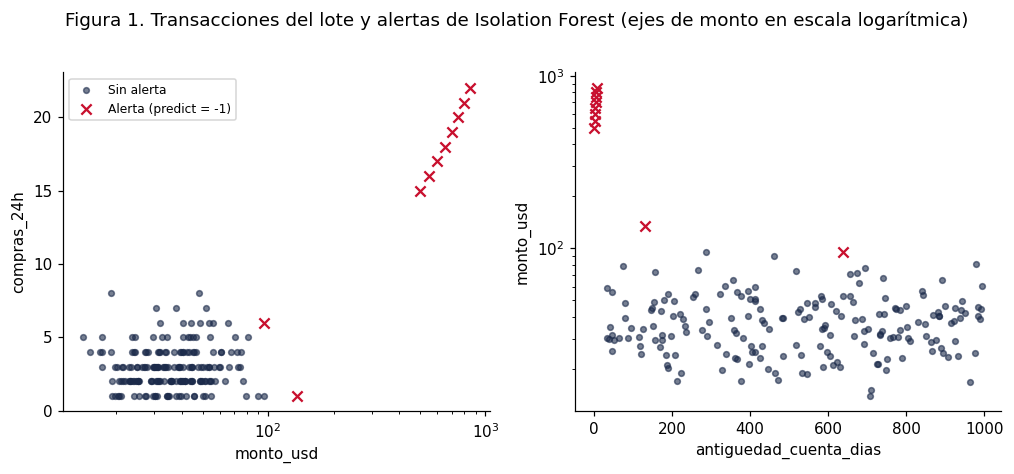

In [20]:
# Calculamos la posición percentil de cada transacción en cada variable
percentiles = transacciones.set_index("transaccion_id")[variables_transaccion].rank(pct=True)

# Comparamos las diez alertas con las medianas del lote
alertas = resultado_bosque[resultado_bosque["alerta"]].copy()
for variable in variables_transaccion:
    alertas[f"{variable}_vs_mediana"] = (alertas[variable] / medianas[variable]).round(2)
    alertas[f"{variable}_percentil"] = alertas["transaccion_id"].map(percentiles[variable]).round(3)
print("Tabla 2. Las diez alertas frente a las medianas del lote")
display(alertas.drop(columns="alerta").round(4))

# Graficamos el lote y resaltamos las alertas
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
normales = resultado_bosque[~resultado_bosque["alerta"]]
for eje, (x, y) in zip(ejes, [("monto_usd", "compras_24h"), ("antiguedad_cuenta_dias", "monto_usd")]):
    eje.scatter(normales[x], normales[y], s=14, color=azul, alpha=0.6, label="Sin alerta")
    eje.scatter(alertas[x], alertas[y], s=45, color=rojo, marker="x", label="Alerta (predict = -1)")
    eje.set(xlabel=x, ylabel=y)
ejes[0].set_xscale("log"); ejes[1].set_yscale("log")
ejes[0].legend(fontsize=8)
fig.suptitle("Figura 1. Transacciones del lote y alertas de Isolation Forest (ejes de monto en escala logarítmica)", y=1.02)
plt.show()

**Comentario de dos registros frente a las medianas del lote (37,33 USD, 3 compras en 24 horas y 520,5 días de antigüedad):**

**T200** es la transacción más rara del lote: 850 USD (unas 23 veces la mediana), 22 compras en 24 horas (más de 7 veces) en una cuenta de solo 8 días. **T193** combina 500 USD (13 veces la mediana) y 15 compras con una cuenta creada hace un día. Ambas se apartan del lote en las tres variables a la vez, la combinación que una regla sobre una sola variable no vería. Antes de actuar revisaríamos el historial de la cuenta, el medio de pago, la entrega y el contacto con el comprador, porque una cuenta nueva que compra mucho también puede ser un cliente corporativo o una compra para un evento. Ninguna de las dos se bloquearía solo por su puntaje: el modelo prioriza la revisión, no confirma fraude.

**Otras observaciones:**

* Las ocho transacciones más raras (T193 a T200) forman un grupo con la misma combinación extrema (montos de 500 a 850 USD, 15 a 22 compras, cuentas de 1 a 8 días). Que aparezcan juntas sugiere un **patrón compartido** que convendría revisar como conjunto, por ejemplo si provienen de un mismo vendedor o medio de pago.
* Las dos alertas restantes son mucho menos extremas: **T140** (135,81 USD, el monto más alto fuera de ese grupo, con una sola compra) y **T163** (95,37 USD y 6 compras en una cuenta de 639 días). Superan el umbral, pero quedan lejos del grupo de las ocho. Aparecen porque `contamination=0.05` obliga a marcar 10 de 200 transacciones (el 5 %): si se fijara otro valor, cambiarían. **Ese 5 % es un umbral didáctico, no una estimación de cuántas compras son fraudulentas.**
* El archivo **no tiene etiquetas**, así que no se puede medir exactitud, precisión ni tasa de falsas alarmas. Esto es una exploración descriptiva de un lote de 200 transacciones, no una evaluación del desempeño sobre datos futuros.

## 8. Recomendación por contenido frente a detección de casos inusuales

| | Bloque A: recomendación por contenido | Bloque B: detección de casos inusuales |
|---|---|---|
| Pregunta | ¿A qué se parece este producto? | ¿Qué tan rara es esta transacción frente al lote? |
| Técnica | TF-IDF y similitud coseno | Isolation Forest |
| Entrada | Descripción de texto | Tres variables numéricas |
| Salida | Lista de productos ordenada por similitud | Puntaje de rareza y alerta |
| Lo que **no** demuestra | Similitud léxica ≠ relevancia para el comprador | Rareza estadística ≠ fraude |
| Validación antes de usarla | Juicios de relevancia por personas sobre consultas representativas, precisión en los primeros resultados y luego una prueba controlada con grupo de control (por ejemplo, valor del carrito) | Revisión humana de las alertas; con los casos confirmados de Seguridad de Pagos, comprobar cuántos habría marcado y cuántas alertas genera; una muestra de casos no marcados para encontrar fallos invisibles |
| Costo de un error | Una recomendación poco útil, fácil de corregir | Un comprador legítimo bloqueado o molestado |

## 9. Recomendación final a la dirección de Compra Ya

**1. ¿Qué proyecto desarrollar primero?**
La **recomendación de productos similares** (área Comercial). Es el único proyecto que cumple las tres condiciones que fijamos al inicio: tiene datos disponibles (las descripciones del catálogo), su resultado se puede validar sin etiquetas previas (juicios de relevancia y luego una prueba controlada) y un error es reversible y no perjudica a nadie. Su impacto es el más predecible y de plazo más corto, y sirve como primer proceso completo para un equipo de dos personas. Seguridad de Pagos es el más urgente, pero con una docena de casos confirmados no se puede estimar cuántas alertas falsas recaerían sobre compradores legítimos; Reseñas falsas no tiene ningún caso confirmado ni datos de reseñas en los recursos.

**2. ¿Con qué técnica y qué datos?**
TF-IDF con unigramas y bigramas sobre la **descripción** de cada producto, limpiada con la misma función para catálogo y consultas, con una lista propia de palabras vacías que conserva negaciones, y similitud coseno para recuperar los productos más parecidos. El `producto_id` se usa para excluir el propio producto y la categoría solo para inspeccionar. Como regla de negocio, se excluyen las copias con descripción idéntica, que se envían a revisión como posibles publicaciones duplicadas.

**3. ¿Cómo validar sin etiquetas?**
En tres etapas: (a) revisión cualitativa como la del Paso 4, con la explicación por términos compartidos; (b) un conjunto de consultas representativas (incluidos sinónimos, abreviaturas, negaciones, textos cortos y términos fuera del vocabulario) con juicios de relevancia hechos por personas del área Comercial, definidos **antes** de comparar configuraciones, midiendo cuántos de los primeros tres resultados son relevantes; y (c) una prueba controlada con un grupo de compradores que sigue viendo "lo más vendido", comparando el valor del carrito y los clics en recomendaciones. Para los proyectos de anomalías, cuando se retomen, los casos confirmados servirían como pequeña muestra de validación, no de entrenamiento.

**4. ¿Qué comunicar a las áreas pospuestas?**
* **Seguridad de Pagos:** que su problema es el más urgente y por eso no se queda sin respuesta. Mientras tanto, pedimos que registre cada reclamo con su resolución (confirmado, descartado o en revisión) y que se guarden historial por cuenta, ubicación y categoría de compra, que hoy no tenemos. El Bloque B muestra que con las variables actuales solo se ve rareza del lote, no robo de cuenta. Estimación honesta: el próximo trimestre, si se reúnen esos datos.
* **Confianza y Seguridad:** que sin ningún caso confirmado no se puede comprobar si un detector acierta. Proponemos que empiece a etiquetar manualmente una muestra de reseñas sospechosas y no sospechosas, y que se guarden fecha, cuenta y texto de cada reseña. Estimación honesta: dentro de dos trimestres.
* **Señales para adelantar un proyecto:** que aumenten los reclamos por compras no reconocidas o su monto; que se acumulen unas decenas de casos confirmados; o que la recomendación quede validada antes de lo previsto y libere capacidad.

**Sobre crecer el equipo:** sugerimos consolidar primero un proceso completo con la recomendación (datos, validación, despliegue y monitoreo manual) antes de sumar más proyectos. Con dos personas, mantener tres sistemas a la vez multiplicaría la carga sin un proceso probado.

**Lo que NO puede afirmarse con este trabajo:**
* Que las recomendaciones sean relevantes para los compradores: solo se comprobó similitud de texto.
* Que el sistema aumente el valor del carrito: eso requiere la prueba controlada.
* Que alguna transacción marcada sea fraudulenta, ni que el 5 % de las compras lo sea.
* Que los resultados se generalicen: ambos archivos son sintéticos y pequeños (120 productos y 200 transacciones).

## 10. Bitácora de decisiones, parámetros y semillas

| # | Decisión | Alternativa considerada | Por qué esta |
|---|---|---|---|
| 1 | Priorizar la recomendación de productos | Seguridad de Pagos (más urgente) | Es el único proyecto con datos, validación posible sin etiquetas y errores reversibles |
| 2 | Leer los CSV desde GitHub con respaldo local | Solo archivos locales | Todo el grupo usa los mismos datos; la huella SHA-256 lo verifica |
| 3 | Vectorizar solo `descripcion` | Concatenar nombre y categoría | Lo pide el enunciado; la categoría se reserva para inspeccionar resultados |
| 4 | Una sola función `limpiar_texto` para catálogo y consultas | Limpiar cada vez de forma distinta | Catálogo y consultas deben quedar en la misma representación |
| 5 | Lista propia de 36 palabras vacías sin negaciones ni *con/sin* | Lista genérica o ninguna | Una lista genérica iguala "con cable" y "sin cable" (similitud 1,000) |
| 6 | Unigramas + bigramas | Solo unigramas | Mismo top 3, pero separan mejor variantes (0,885 → 0,777) y capturan expresiones |
| 7 | Excluir el propio producto por `producto_id` | Quitar la primera posición | Con empates en 1,000 la primera posición no es necesariamente el propio producto |
| 8 | Desempate estable por orden del catálogo | Orden arbitrario | Resultados reproducibles |
| 9 | Diagonal verificada con `atol=1e-10` | Igualdad exacta | Evita falsos errores por coma flotante |
| 10 | Consulta con vector nulo → "sin coincidencias" | Ordenar por similitud 0 | Mostraría productos arbitrarios como si fueran relevantes |
| 11 | `transform` para consultas y productos nuevos | `fit_transform` | Conserva vocabulario y pesos del catálogo |
| 12 | Excluir copias idénticas como regla de negocio | Recomendar copias | Las copias no ayudan a descubrir y sugieren publicaciones duplicadas |
| 13 | Isolation Forest con 100 árboles y `contamination=0.05`, sin estandarizar | Buscar parámetros o escalar | Configuración fija del enunciado; el algoritmo no usa distancias |
| 14 | Presentar $-$`score_samples` | `score_samples` directo | Mayor valor = más rara, más fácil de leer |

**Semillas:** 42 en `sample` (muestra aleatoria del Paso 1) y en `IsolationForest`. TF-IDF y la similitud coseno son deterministas.